<a href="https://colab.research.google.com/github/farahdinaariff/Data-Science-Project/blob/main/TropicalPV_Probabilistic_Solar_Forecasting_v8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TropicalPV — v5 vs v6 Timestamp Handling: What Was Wrong, What Changed, and What Actually Corrected It

**Author:** Farah Dina Bte Esa Mahmud Ariff — MSc Data Science (7FTC2001)
**Purpose:** a reproducible, evidence-based demonstration of how the Darwin (DKASC NT Class A 7127) timestamps were read in pipeline **v5** and **v6**, why that reading is wrong, how it distorts the data used for modelling, and how it should be read.

---

### Key finding, stated up front (the notebook demonstrates each part)

The premise "v5 had the timestamp error and v6 corrected it" is **only half true**. Two different timing problems existed, and they were fixed in different versions.

| Problem | v5 | v6 | v7 |
|---|---|---|---|
| **A. Wrong time reference.** The DKASC `Timestamp_Local` column is **UTC+9:00**, but Darwin's legal standard time (ACST) is **UTC+9:30** | Present: hourly bins built from `Timestamp_Local` | **Still present:** same column, same code | **Corrected:** bins built from `Timestamp_UTC` + 9 h 30 min |
| **B. Wrong instant within the hour.** An hourly mean represents the middle of the hour (~HH:30), but the sun was evaluated at HH:00 | Present | **Corrected:** sun evaluated at the mean sample time of each bin | Corrected (kept) |

Consequences:

* **v5** was mistimed by about **−60 min** against the sun: A and B add up.
* **v6** removed B only, so a **~−30 min** error remained.
* **v7** removed both.

Problem A changes **the hourly values themselves** (which one-second samples fall in each hour) as well as their labels, so it affects the **modelling data**, not only its interpretation. Problem B changes no hourly value; it changes the clear-sky index derived from the values.

The pipeline's own code (quoted in §3–4) and the physics of solar noon in the raw one-second data (§8–12) are the evidence. No model is trained in this notebook.

## 1. Research context

The forecasting target is the **clear-sky index** k_t = GHI / GHI_clear-sky, one hour ahead. It removes the daily solar cycle and leaves only cloud effects. It is only correct if the measured GHI and the computed clear-sky GHI refer to **the same instant**. The clear-sky value comes from solar geometry, which is computed from a timestamp. A timestamp that is 30 or 60 minutes off therefore puts the computed sun in the wrong place relative to the measurement:

* In the morning, the sun is placed too low. GHI_cs is then too small and k_t too high.
* In the afternoon the opposite happens.

This distortion feeds the target, the persistence baseline, the quality-control ceiling on k_t, and the ramp definition (|Δk_t| > 0.35). All of these enter the forecasting results.

**Darwin does not observe daylight saving time.** The Northern Territory stays on ACST (UTC+9:30) all year, so any correct local timestamp must differ from UTC by exactly 9 h 30 min on every row. §5 tests this directly.

## 2. Load the required files

**What.** Mount Google Drive, locate one Darwin 1-second irradiance file, and read **only a bounded window** (default: July 2022, dry season, mostly clear skies).

**Why.** The timing error is a property of every row, so one month demonstrates it completely. Reading a whole year of 1-second data (~31 million rows) is not needed. Clear days are required because solar noon can only be read from the data when clouds do not distort the daily curve.

**Performance.** The file is streamed in chunks and reading stops once the window has passed, so memory is bounded. Scanning up to July takes about 1–2 minutes in Colab. Nothing is modelled.

Edit the configuration cell if your file names or the preferred month differ.

In [ ]:
# ---- configuration (edit here only) ----------------------------------------------------------
import os, glob, re, sys, time, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = os.path.exists("/content")
if IN_COLAB and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

DATA_ROOT   = os.environ.get("TROPICALPV_ROOT", "/content/drive/MyDrive")
FILE_GLOB   = "**/fsm1m_7127*darwin*irradiancedata_1sec_2022*.csv"   # one Darwin 1-s annual file
WINDOW_UTC  = ("2022-07-01", "2022-08-01")     # [start, end) — dry season, many clear days
CHUNK_ROWS  = 1_000_000
RUN_FULL_YEAR_RAMP_CHECK = False               # optional §12.4 (reads the whole file; ~3-5 min)

# Site constants — identical to the pipeline's SITES["DARWIN"] (v5, v6, v7)
LAT, LON = -12.4256, 130.8916
ACST_OFFSET_H = 9.5                            # Australian Central Standard Time, no DST in the NT
KT_MAX, DAYLIGHT_CS_MIN, RAMP_KT = 1.30, 20.0, 0.35
SOLAR_CONSTANT = 1367.0

hits = sorted(glob.glob(os.path.join(DATA_ROOT, FILE_GLOB), recursive=True))
print("Files matching FILE_GLOB:", *hits, sep="\n  ")
assert hits, ("No Darwin 1-s file found. Check DATA_ROOT and FILE_GLOB "
              "(file names look like fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv).")
DARWIN_FILE = hits[0]
print(f"\nUsing: {DARWIN_FILE}  ({os.path.getsize(DARWIN_FILE)/1e6:,.0f} MB)")

Mounted at /content/drive
Files matching FILE_GLOB:
  /content/drive/MyDrive/Data-DKASC Darwin/fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv
  /content/drive/MyDrive/Data_Australia Tropical Class A irradiance-Darwin-Katherine/fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv

Using: /content/drive/MyDrive/Data-DKASC Darwin/fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv  (2,418 MB)


### 2.1 Inspect the raw file header, with no parsing and no assumptions

**What.** Print the first lines exactly as they are stored.
**Why.** Before any code interprets a timestamp, the reader should see what the file itself says: two timestamp columns, one labelled UTC and one labelled Local.

In [ ]:
with open(DARWIN_FILE, "r", encoding="utf-8-sig", errors="replace") as f:
    head_lines = [next(f) for _ in range(6)]
header_idx = next(i for i, l in enumerate(head_lines) if "timestamp_utc" in l.lower())
print(f"Header found on line {header_idx}. Raw first lines:\n")
for l in head_lines:
    print("  " + l.rstrip())

Header found on line 0. Raw first lines:

  Timestamp_UTC [DD/MM/YYYY hh:mm:ss],Timestamp_Local [DD/MM/YYYY hh:mm:ss],Irradiance_MB0 [W/m-2],UnitTemp_MB0 [deg C],Voltage_MB0 [V],Irradiance_MB1 [W/m-2],UnitTemp_MB1 [deg C],Voltage_MB1 [V],Timestamp_UNIX [s],Hour_UTC,Hour_Local
  01/01/2022 00:00:00,01/01/2022 09:00:00,,,,,,,,00,09
  01/01/2022 00:00:01,01/01/2022 09:00:01,,,,,,,,00,09
  01/01/2022 00:00:02,01/01/2022 09:00:02,,,,,,,,00,09
  01/01/2022 00:00:03,01/01/2022 09:00:03,,,,,,,,00,09
  01/01/2022 00:00:04,01/01/2022 09:00:04,,,,,,,,00,09


In [ ]:
# ---- stream the window: raw strings are kept exactly as stored --------------------------------
cols_all = pd.read_csv(DARWIN_FILE, skiprows=header_idx, nrows=0).columns.tolist()
COL_UTC   = next(c for c in cols_all if c.lower().startswith("timestamp_utc"))
COL_LOCAL = next(c for c in cols_all if c.lower().startswith("timestamp_local"))
COLS_IRR  = [c for c in cols_all if c.lower().startswith("irradiance_mb")]
print("Timestamp columns :", COL_UTC, "|", COL_LOCAL)
print("Irradiance columns:", COLS_IRR)

w0, w1 = pd.Timestamp(WINDOW_UTC[0]), pd.Timestamp(WINDOW_UTC[1])
kept, scanned, t_start = [], 0, time.time()
reader = pd.read_csv(DARWIN_FILE, skiprows=header_idx, usecols=[COL_UTC, COL_LOCAL] + COLS_IRR,
                     dtype={COL_UTC: str, COL_LOCAL: str}, chunksize=CHUNK_ROWS)
for chunk in reader:
    scanned += len(chunk)
    t_utc = pd.to_datetime(chunk[COL_UTC], dayfirst=True, errors="coerce")
    sel = (t_utc >= w0) & (t_utc < w1)
    if sel.any():
        kept.append(chunk[sel])
    if t_utc.notna().any() and t_utc.min() >= w1:     # file is time-ordered: stop after the window
        break
print(f"\nScanned {scanned:,} rows in {time.time()-t_start:.0f}s")
assert kept, f"No rows inside WINDOW_UTC {WINDOW_UTC}; choose a window inside this file."

df_raw = pd.concat(kept, ignore_index=True)          # <- the untouched raw observations
df_raw[COLS_IRR] = df_raw[COLS_IRR].apply(pd.to_numeric, errors="coerce")
df_raw["ghi_wm2"] = df_raw[COLS_IRR].mean(axis=1)    # same as all versions: mean of the two reference cells
df_raw.loc[(df_raw.ghi_wm2 >= 9000) | (df_raw.ghi_wm2 <= -999), "ghi_wm2"] = np.nan   # logger fill codes
N_RAW = len(df_raw)
print(f"Rows in window: {N_RAW:,}")
df_raw.head()

Timestamp columns : Timestamp_UTC [DD/MM/YYYY hh:mm:ss] | Timestamp_Local [DD/MM/YYYY hh:mm:ss]
Irradiance columns: ['Irradiance_MB0 [W/m-2]', 'Irradiance_MB1 [W/m-2]']

Scanned 20,000,000 rows in 104s
Rows in window: 2,678,400


,Timestamp_UTC [DD/MM/YYYY hh:mm:ss],Timestamp_Local [DD/MM/YYYY hh:mm:ss],Irradiance_MB0 [W/m-2],Irradiance_MB1 [W/m-2],ghi_wm2
0,01/07/2022 00:00:00,01/07/2022 09:00:00,80.0,76.0,78.0
1,01/07/2022 00:00:01,01/07/2022 09:00:01,80.0,76.0,78.0
2,01/07/2022 00:00:02,01/07/2022 09:00:02,79.0,76.0,77.5
3,01/07/2022 00:00:03,01/07/2022 09:00:03,79.0,76.0,77.5
4,01/07/2022 00:00:04,01/07/2022 09:00:04,79.0,76.0,77.5


## 3. Inspect the v5 timestamp handling (quoted from the v5 notebook)

v5 builds Darwin's hourly series in `load_darwin()` (v5 cell 17) from the **local** column:

```python
h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M:%S",
                     irr + tmp, DKASC_IRR_TOKENS, max_rows=CFG.MAX_ROWS_PER_FILE)
```

`stream_to_hourly` parses that string as a **timezone-naive** datetime, floors it to the hour, and averages every sample in the hour. The result is labelled with the hour's **start** (HH:00).

Solar geometry (v5 cell 9) is then evaluated directly at that label:

```python
def attach_solar(df, site):
    cosz, toa = solar_geometry(pd.DatetimeIndex(df["ts"]), m["lat"], m["lon"], m["tz"])
```

`solar_geometry` treats its input as **local standard time** with `tz = 9.5`, i.e. it assumes the label is ACST.

**The two assumptions v5 makes, both implicit:**

1. `Timestamp_Local` is ACST (UTC+9:30).
2. An hourly mean describes the instant HH:00.

## 4. Inspect the v6 timestamp handling (quoted from the v6 notebook)

v6's `load_darwin()` (v6 cell 20) reads **the same column with the same call**:

```python
h = stream_to_hourly(p, "timestamp_local", "%d/%m/%Y %H:%M:%S",
                     irr + tmp, DKASC_IRR_TOKENS, max_rows=CFG.MAX_ROWS_PER_FILE)
```

What v6 **added** (v6 cell 12, `CFG.GEOMETRY_TIMING = "sample_centre"`):

```python
def geometry_times(df, site):
    # "Every loader labels an hourly row with the START of its hour (HH:00), but the value is
    #  the mean of the samples inside that hour, whose centre is ~HH:30 ..."
    return ts + pd.to_timedelta(off, unit="m")        # off = mean sample offset in the bin (ts_off_min)
```

So v6 changed **where within the hour the sun is evaluated** (assumption 2). It did **not** change which column defines the hour (assumption 1).

| Question | Answer |
|---|---|
| Did v6 change the timestamp column? | No: still `Timestamp_Local` |
| Did v6 change any hourly GHI value? | No: identical bins, so identical means (verified in §9) |
| Did v6 change the modelling data? | Yes, through k_t: GHI_cs is now computed at ~HH:30 instead of HH:00 |
| Is v6's result correct? | Only if `Timestamp_Local` is ACST. §5 shows it is not. |

## 5. Raw timestamp comparison: what does `Timestamp_Local` actually mean?

**What.** For every row, subtract the UTC timestamp from the local timestamp. Both are parsed with the same format, and neither is shifted.
**Why.** If `Timestamp_Local` were ACST, the difference would be exactly **+9.50 h on every row**, because Darwin has no DST.

In [ ]:
raw_utc   = pd.to_datetime(df_raw[COL_UTC],   dayfirst=True, errors="coerce")
raw_local = pd.to_datetime(df_raw[COL_LOCAL], dayfirst=True, errors="coerce")
offset_h  = (raw_local - raw_utc).dt.total_seconds() / 3600

offset_table = offset_h.value_counts(dropna=False).rename_axis("Local − UTC (h)").to_frame("rows")
offset_table["share_%"] = 100 * offset_table["rows"] / offset_table["rows"].sum()
print("Distribution of (Timestamp_Local − Timestamp_UTC) over every row in the window:")
display(offset_table)
FILE_LOCAL_OFFSET_H = float(offset_h.mode().iloc[0])
print(f"\nFile's local offset: UTC{FILE_LOCAL_OFFSET_H:+.2f} h   |   ACST (legal, NT): UTC+{ACST_OFFSET_H:.2f} h"
      f"   |   discrepancy: {60*(FILE_LOCAL_OFFSET_H-ACST_OFFSET_H):+.0f} min")
print("Timezone metadata in the file: none (both columns are naive strings; the zone is only in the column name)")

Distribution of (Timestamp_Local − Timestamp_UTC) over every row in the window:


,rows,share_%
Local − UTC (h),,
9.0,2678400,100.0



File's local offset: UTC+9.00 h   |   ACST (legal, NT): UTC+9.50 h   |   discrepancy: -30 min
Timezone metadata in the file: none (both columns are naive strings; the zone is only in the column name)


**Result and interpretation.** Read the printed table. On the DKASC exports, the pipeline's own check over 11 files (v7 Part 3.2, `tz_check`) recorded **9.0 h on every file**, i.e. the `Local` column is **UTC+9:00, 30 minutes behind ACST**.

A reader, or a pipeline, that takes the column name at face value places every sample **30 minutes earlier** than it really occurred. The offset is constant, so there is no DST switching and no mixture. It is a fixed reference error, not noise.

Which column is right cannot be settled by the column names alone. It is settled by **physics** (§8): the sun is highest at a calculable instant each day.

## 6. Parsed timestamps: the three interpretations of the same rows

**What.** Build three explicit timestamp series for **the same raw rows**, without modifying `df_raw`:

* `timestamp_v5`: the local column, parsed as is (v5 **and** v6 use this)
* `timestamp_v6`: identical to `timestamp_v5`; v6 differs only later, in geometry
* `timestamp_v7`: the UTC column + 9 h 30 min, i.e. true ACST

**Validation.** The number of rows is unchanged, and the ordering, duplicates and sampling interval are checked for each series.

In [ ]:
timestamp_v5 = raw_local.copy()                                   # v5: Timestamp_Local, naive, as ACST
timestamp_v6 = raw_local.copy()                                   # v6: identical column (see §4)
timestamp_v7 = raw_utc + pd.Timedelta(hours=ACST_OFFSET_H)        # v7: UTC + 9:30 = ACST

def check(name, t):
    d = t.diff().dropna()
    return {"series": name, "rows": len(t), "unparseable": int(t.isna().sum()),
            "first": t.min(), "last": t.max(), "monotonic": bool(t.is_monotonic_increasing),
            "duplicates": int(t.duplicated().sum()), "median_step_s": d.dt.total_seconds().median(),
            "gaps_>1min": int((d > pd.Timedelta(minutes=1)).sum())}

validation_parsed = pd.DataFrame([check("timestamp_v5", timestamp_v5),
                                  check("timestamp_v6", timestamp_v6),
                                  check("timestamp_v7", timestamp_v7)])
display(validation_parsed)
assert len(timestamp_v5) == len(timestamp_v7) == N_RAW, "row count changed"
print("Shift v7 − v5 (every row):", ((timestamp_v7 - timestamp_v5).dt.total_seconds() / 60).unique(), "minutes")

,series,rows,unparseable,first,last,monotonic,duplicates,median_step_s,gaps_>1min
0,timestamp_v5,2678400,0,2022-07-01 09:00:00,2022-08-01 08:59:59,True,0,1.0,0
1,timestamp_v6,2678400,0,2022-07-01 09:00:00,2022-08-01 08:59:59,True,0,1.0,0
2,timestamp_v7,2678400,0,2022-07-01 09:30:00,2022-08-01 09:29:59,True,0,1.0,0


Shift v7 − v5 (every row): [30.] minutes


## 7. Timezone / temporal interpretation: side-by-side for the same observations

**What.** The same raw rows under each interpretation, sampled at the top of each hour of one day.
**Why.** This makes it immediately visible that one physical measurement receives two different clock times.

In [ ]:
day0 = timestamp_v7.dt.normalize().value_counts().index.sort_values()[len(timestamp_v7.dt.normalize().unique()) // 2]
m = (timestamp_v7.dt.normalize() == day0) & (timestamp_v7.dt.minute == 0) & (timestamp_v7.dt.second == 0)
side = pd.DataFrame({"Observation (raw row)": df_raw.index[m],
                     "raw Timestamp_UTC": df_raw.loc[m, COL_UTC].values,
                     "raw Timestamp_Local": df_raw.loc[m, COL_LOCAL].values,
                     "v5/v6 reading (ACST?)": timestamp_v5[m].dt.strftime("%Y-%m-%d %H:%M").values,
                     "v7 reading (true ACST)": timestamp_v7[m].dt.strftime("%Y-%m-%d %H:%M").values,
                     "Difference (min)": ((timestamp_v7[m] - timestamp_v5[m]).dt.total_seconds() / 60).values,
                     "GHI (W/m²)": df_raw.loc[m, "ghi_wm2"].round(1).values})
side["Interpretation"] = np.where(side["GHI (W/m²)"] > 5,
    "same measurement; v5/v6 place it 30 min earlier than it occurred", "night: timing invisible")
print(f"Day shown: {day0.date()}  (true ACST)")
display(side.head(24))

Day shown: 2022-07-17  (true ACST)


,Observation (raw row),raw Timestamp_UTC,raw Timestamp_Local,v5/v6 reading (ACST?),v7 reading (true ACST),Difference (min),GHI (W/m²),Interpretation
0,1348200,16/07/2022 14:30:00,16/07/2022 23:30:00,2022-07-16 23:30,2022-07-17 00:00,30.0,0.0,night: timing invisible
1,1351800,16/07/2022 15:30:00,17/07/2022 00:30:00,2022-07-17 00:30,2022-07-17 01:00,30.0,0.0,night: timing invisible
2,1355400,16/07/2022 16:30:00,17/07/2022 01:30:00,2022-07-17 01:30,2022-07-17 02:00,30.0,0.0,night: timing invisible
3,1359000,16/07/2022 17:30:00,17/07/2022 02:30:00,2022-07-17 02:30,2022-07-17 03:00,30.0,0.0,night: timing invisible
4,1362600,16/07/2022 18:30:00,17/07/2022 03:30:00,2022-07-17 03:30,2022-07-17 04:00,30.0,0.0,night: timing invisible
5,1366200,16/07/2022 19:30:00,17/07/2022 04:30:00,2022-07-17 04:30,2022-07-17 05:00,30.0,0.0,night: timing invisible
6,1369800,16/07/2022 20:30:00,17/07/2022 05:30:00,2022-07-17 05:30,2022-07-17 06:00,30.0,0.0,night: timing invisible
7,1373400,16/07/2022 21:30:00,17/07/2022 06:30:00,2022-07-17 06:30,2022-07-17 07:00,30.0,0.5,night: timing invisible
8,1377000,16/07/2022 22:30:00,17/07/2022 07:30:00,2022-07-17 07:30,2022-07-17 08:00,30.0,122.5,same measurement; v5/v6 place it 30 min earlie...
9,1380600,16/07/2022 23:30:00,17/07/2022 08:30:00,2022-07-17 08:30,2022-07-17 09:00,30.0,374.5,same measurement; v5/v6 place it 30 min earlie...


## 8. The v5 problem, demonstrated from the physics (native 1-second data, no model)

**What.** For every clear day, compute two things and compare them:

1. **Physical solar noon:** the instant the sun is highest, from the standard astronomical formula. It depends only on longitude and date (equation of time).
2. **Observed solar noon:** the irradiance-weighted centre of the day's measured curve, and the mid-point between the morning and evening 50 W/m² crossings.

Both observed estimates are computed on the **1-second samples**. There is no hourly binning and no clear-sky model.

**Why.** On a clear day the irradiance curve is symmetric about solar noon, so the observed centre must fall on the physical noon **in the correct time basis**. Whichever timestamp series puts the observed noon on the physical noon is the correct one.

Clear days are selected from the raw data by daily-profile smoothness (see code). The selection does not depend on which timestamp series is used.

In [ ]:
def eot_minutes(doy):
    g = 2 * np.pi * (np.asarray(doy, float) - 1) / 365.0
    return 229.18 * (0.000075 + 0.001868*np.cos(g) - 0.032077*np.sin(g) - 0.014615*np.cos(2*g) - 0.040849*np.sin(2*g))

def physical_solar_noon_acst_hours(dates):
    # NOAA: solar noon (local standard) = 720 - 4*lon - EoT + 60*tz  [minutes]
    return (720 - 4*LON - eot_minutes(pd.DatetimeIndex(dates).dayofyear) + 60*ACST_OFFSET_H) / 60.0

# --- clear-day selection, independent of the timestamp choice: a clear day has a smooth curve,
#     i.e. small 1-minute changes relative to its peak (computed on raw row order).
g = df_raw["ghi_wm2"].to_numpy()
day_key = timestamp_v7.dt.normalize()                    # grouping only; a 30-min shift does not change which
stats = []                                               # midday samples dominate a day
for d, idx in pd.Series(np.arange(N_RAW)).groupby(day_key.values):
    gi = g[idx.values]
    if np.nanmax(gi) < 500 or np.isnan(gi).mean() > 0.05:
        continue
    step = max(1, int(round(60 / validation_parsed.median_step_s.iloc[0])))
    rough = np.nanmean(np.abs(np.diff(gi[::step]))) / np.nanmax(gi)
    stats.append({"day": d, "peak_Wm2": np.nanmax(gi), "roughness": rough})
day_stats = pd.DataFrame(stats)
CLEAR_DAYS = day_stats.nsmallest(max(3, len(day_stats) // 3), "roughness")["day"].sort_values().tolist()
print(f"Days with data: {len(day_stats)};  clearest third used: {len(CLEAR_DAYS)} days")

def observed_noon_hours(t, ghi):
    h = t.dt.hour + t.dt.minute/60 + t.dt.second/3600
    w = np.clip(np.nan_to_num(ghi), 0, None)
    centroid = float((h*w).sum() / w.sum())
    above = h[ghi > 50]
    return centroid, float((above.min() + above.max()) / 2)

rows = []
for d in CLEAR_DAYS:
    sel = (day_key == d).to_numpy()
    c5, m5 = observed_noon_hours(timestamp_v5[sel], df_raw.ghi_wm2[sel])
    c7, m7 = observed_noon_hours(timestamp_v7[sel], df_raw.ghi_wm2[sel])
    noon = physical_solar_noon_acst_hours([d])[0]
    rows.append({"day": d.date(), "physical noon (ACST)": noon,
                 "v5/v6 centroid − noon (min)": 60*(c5-noon), "v5/v6 mid-crossing − noon (min)": 60*(m5-noon),
                 "v7 centroid − noon (min)": 60*(c7-noon), "v7 mid-crossing − noon (min)": 60*(m7-noon)})
noon_check = pd.DataFrame(rows)
fmt = lambda h: f"{int(h):02d}:{int(round((h % 1)*60)):02d}"
noon_check["physical noon (ACST)"] = noon_check["physical noon (ACST)"].map(fmt)
display(noon_check.round(1))
noon_summary = noon_check.drop(columns=["day", "physical noon (ACST)"]).agg(["mean", "std"]).round(1)
display(noon_summary)

Days with data: 32;  clearest third used: 10 days


,day,physical noon (ACST),v5/v6 centroid − noon (min),v5/v6 mid-crossing − noon (min),v7 centroid − noon (min),v7 mid-crossing − noon (min)
0,2022-07-05,12:51,-29.8,-30.7,0.2,-0.7
1,2022-07-06,12:51,-30.4,-28.4,-0.4,1.6
2,2022-07-07,12:51,-30.5,-31.5,-0.5,-1.5
3,2022-07-08,12:51,-30.3,-30.0,-0.3,-0.0
4,2022-07-09,12:51,-30.6,-30.9,-0.6,-0.9
5,2022-07-11,12:52,-30.2,-30.6,-0.2,-0.6
6,2022-07-14,12:52,-30.8,-31.3,-0.8,-1.3
7,2022-07-15,12:52,-32.6,-31.1,-2.6,-1.1
8,2022-07-20,12:53,-31.7,-31.8,-1.7,-1.8
9,2022-07-24,12:53,-31.3,-29.9,-1.3,0.1


,v5/v6 centroid − noon (min),v5/v6 mid-crossing − noon (min),v7 centroid − noon (min),v7 mid-crossing − noon (min)
mean,-30.8,-30.6,-0.8,-0.6
std,0.8,1.0,0.8,1.0


**Result.** Read the summary row:

* The **v5/v6** reading (`Timestamp_Local`) puts the observed centre of every clear day about **30 minutes before** the physical solar noon.
* The **v7** reading (UTC + 9:30) puts it on the solar noon, within a few minutes.

Both observed estimators (centroid and mid-crossing) agree.

**Interpretation.** This is the decisive evidence. The sun is at its highest point at a known instant. Only the UTC-derived timestamps agree with it, so `Timestamp_Local` is not ACST. The error is in the **time reference**, not in the irradiance values: the raw measurements are the same numbers in both readings.

## 9. The v5 problem, as it enters the hourly modelling data

**What.** Reproduce, for the same window, the hourly aggregation and clear-sky index **exactly as each version computed it**:

* **v5:** bins from `timestamp_v5`, sun evaluated at the bin label (HH:00)

This cell shows the problematic implementation only. The corrections follow in separate cells.

In [ ]:
# ---------- shared, version-independent physics (verbatim from the pipeline) ----------
def solar_geometry(ts_local, lat, lon, tz):
    utc = pd.DatetimeIndex(ts_local) - pd.Timedelta(hours=tz)
    doy = np.asarray(utc.dayofyear, dtype=float)
    hod = np.asarray(utc.hour, float) + np.asarray(utc.minute, float)/60 + np.asarray(utc.second, float)/3600
    gg = 2*np.pi*(doy - 1 + (hod - 12)/24)/365
    eqtime = 229.18*(0.000075 + 0.001868*np.cos(gg) - 0.032077*np.sin(gg) - 0.014615*np.cos(2*gg) - 0.040849*np.sin(2*gg))
    decl = (0.006918 - 0.399912*np.cos(gg) + 0.070257*np.sin(gg) - 0.006758*np.cos(2*gg)
            + 0.000907*np.sin(2*gg) - 0.002697*np.cos(3*gg) + 0.001480*np.sin(3*gg))
    ha = np.radians((hod*60 + eqtime + 4*lon)/4 - 180)
    la = np.radians(lat)
    return np.clip(np.sin(la)*np.sin(decl) + np.cos(la)*np.cos(decl)*np.cos(ha), -1, 1)

def clearsky_haurwitz(cosz):
    c = np.where(cosz > 0, cosz, np.nan)
    with np.errstate(all="ignore"):
        return np.nan_to_num(1098.0*c*np.exp(-0.059/c))

In [ ]:
# ---------- v5: PROBLEMATIC implementation ----------
tmp = pd.DataFrame({"t": timestamp_v5, "ghi": df_raw["ghi_wm2"]})
tmp["label"] = tmp["t"].dt.floor("h")                                   # bin = hour of Timestamp_Local
hourly_v5 = tmp.groupby("label").agg(ghi_wm2=("ghi", "mean"), n_obs=("ghi", "size"),
                                     mean_t=("t", "mean")).reset_index().rename(columns={"label": "ts"})
geom_v5 = pd.DatetimeIndex(hourly_v5["ts"])                              # sun evaluated at HH:00
hourly_v5["ghi_cs"] = clearsky_haurwitz(solar_geometry(geom_v5, LAT, LON, ACST_OFFSET_H))
hourly_v5["kt"] = np.where(hourly_v5.ghi_cs > DAYLIGHT_CS_MIN, hourly_v5.ghi_wm2 / hourly_v5.ghi_cs, np.nan)
print(f"v5 hourly rows: {len(hourly_v5):,}   samples aggregated: {hourly_v5.n_obs.sum():,} (raw {N_RAW:,})")
hourly_v5.head(3)

v5 hourly rows: 744   samples aggregated: 2,678,400 (raw 2,678,400)


,ts,ghi_wm2,n_obs,mean_t,ghi_cs,kt
0,2022-07-01 09:00:00,113.521389,3600,2022-07-01 09:29:59.500,376.958435,0.301151
1,2022-07-01 10:00:00,230.370417,3600,2022-07-01 10:29:59.500,572.512917,0.402385
2,2022-07-01 11:00:00,340.394861,3600,2022-07-01 11:29:59.500,719.315919,0.473220


**What the v5 code is doing.** Each hour of `Timestamp_Local` is averaged and labelled HH:00, and the sun is computed at HH:00 ACST.

**Why it is wrong.**

* The averaged samples truly span ACST **HH:30–HH+1:30**, because the local column is 30 min behind ACST. Their centre is therefore at ACST **HH+1:00**, but the sun is computed at HH:00.
* The combined error is **about 60 minutes**: 30 min from the time reference plus 30 min from the within-hour instant.

**What a reader would wrongly conclude.**

* The clear-sky model looks systematically "late": morning k_t is too high and afternoon k_t too low.
* A clear day looks like a morning with cloud enhancement followed by an afternoon with thin cloud.

## 10. The v6 change: a partial correction (separate cell)

**What.** v6 keeps the v5 bins and evaluates the sun at the **mean sample time of each bin** (`ts_off_min`) instead of HH:00.

In [ ]:
# ---------- v6: PARTIAL correction (geometry instant only) ----------
hourly_v6 = hourly_v5[["ts", "ghi_wm2", "n_obs", "mean_t"]].copy()          # identical bins and values
hourly_v6["ts_off_min"] = (hourly_v6["mean_t"] - hourly_v6["ts"]).dt.total_seconds() / 60
geom_v6 = pd.DatetimeIndex(hourly_v6["ts"]) + pd.to_timedelta(hourly_v6["ts_off_min"], unit="m")
hourly_v6["ghi_cs"] = clearsky_haurwitz(solar_geometry(geom_v6, LAT, LON, ACST_OFFSET_H))
hourly_v6["kt"] = np.where(hourly_v6.ghi_cs > DAYLIGHT_CS_MIN, hourly_v6.ghi_wm2 / hourly_v6.ghi_cs, np.nan)

same_values = np.allclose(hourly_v5.ghi_wm2, hourly_v6.ghi_wm2, equal_nan=True)
print(f"Median within-bin offset applied by v6: {hourly_v6.ts_off_min.median():.1f} min")
print(f"Are v5 and v6 hourly GHI values identical?  {same_values}   (expected True: v6 changed geometry only)")
assert same_values

Median within-bin offset applied by v6: 30.0 min
Are v5 and v6 hourly GHI values identical?  True   (expected True: v6 changed geometry only)


**What changed.** Only the instant at which the sun is computed: ~HH:30 instead of HH:00. This is technically correct **for the bin as labelled**.

**What did not change.** The bin still consists of `Timestamp_Local` HH:00–HH:59, i.e. true ACST HH:30–HH+1:29. The sun is now computed at local HH:30, which is really ACST HH+1:00 in time, but the pipeline evaluates it as ACST HH:30. **A 30-minute error remains.**

**Consequence.** v6 halved the distortion but did not remove it. The GHI values are identical to v5 (verified above), so v6 changed the **derived** modelling data (k_t) but not the measurements.

## 11. The actual correction (v7): read the UTC column and convert to ACST

**What.** Bins are built from `timestamp_v7` (UTC + 9:30), and the sun is evaluated at the mean sample time, as in v6.

**Why this is correct.**

* `Timestamp_UTC` is unambiguous.
* ACST = UTC+9:30 all year in the Northern Territory.
* The physical solar-noon test (§8) confirms the result independently.

In [ ]:
# ---------- v7: CORRECTED implementation ----------
tmp7 = pd.DataFrame({"t": timestamp_v7, "ghi": df_raw["ghi_wm2"]})
tmp7["label"] = tmp7["t"].dt.floor("h")                                  # bin = true ACST hour
hourly_v7 = tmp7.groupby("label").agg(ghi_wm2=("ghi", "mean"), n_obs=("ghi", "size"),
                                      mean_t=("t", "mean")).reset_index().rename(columns={"label": "ts"})
hourly_v7["ts_off_min"] = (hourly_v7["mean_t"] - hourly_v7["ts"]).dt.total_seconds() / 60
geom_v7 = pd.DatetimeIndex(hourly_v7["ts"]) + pd.to_timedelta(hourly_v7["ts_off_min"], unit="m")
hourly_v7["ghi_cs"] = clearsky_haurwitz(solar_geometry(geom_v7, LAT, LON, ACST_OFFSET_H))
hourly_v7["kt"] = np.where(hourly_v7.ghi_cs > DAYLIGHT_CS_MIN, hourly_v7.ghi_wm2 / hourly_v7.ghi_cs, np.nan)

# validation: nothing dropped, only regrouped
assert hourly_v7.n_obs.sum() == hourly_v5.n_obs.sum() == N_RAW
print(f"Samples aggregated — v5: {hourly_v5.n_obs.sum():,} | v7: {hourly_v7.n_obs.sum():,} | raw: {N_RAW:,}")
print(f"Hourly rows — v5: {len(hourly_v5):,} | v7: {len(hourly_v7):,}")

Samples aggregated — v5: 2,678,400 | v7: 2,678,400 | raw: 2,678,400
Hourly rows — v5: 744 | v7: 745


## 12. Direct before/after comparison

### 12.1 Same hour label, different measurements

**What.** Join the v5 and v7 hourly tables on the label (e.g. "12:00").

**Why.** This shows that the error is not only a relabelling. The v5 "12:00" hour averages a **different half-hour window** of physical time than the true ACST 12:00 hour, so the hourly values themselves differ.

In [ ]:
cmp = hourly_v5[["ts", "ghi_wm2", "kt"]].merge(hourly_v6[["ts", "kt"]], on="ts", suffixes=("_v5", "_v6")) \
                                        .merge(hourly_v7[["ts", "ghi_wm2", "kt"]].rename(columns={"ghi_wm2": "ghi_wm2_v7", "kt": "kt_v7"}), on="ts")
cmp = cmp.rename(columns={"ghi_wm2": "ghi_wm2_v5"})
cmp["true ACST window of v5 label"] = (cmp.ts + pd.Timedelta(minutes=30)).dt.strftime("%H:%M") + "–" + \
                                      (cmp.ts + pd.Timedelta(minutes=90)).dt.strftime("%H:%M")
one = cmp[cmp.ts.dt.normalize() == pd.Timestamp(CLEAR_DAYS[len(CLEAR_DAYS)//2])]
one = one[one.ghi_wm2_v7 > 5]
display(one.assign(ts=one.ts.dt.strftime("%H:%M")).rename(columns={"ts": "hour label"}).round(3))

,hour label,ghi_wm2_v5,kt_v5,kt_v6,ghi_wm2_v7,kt_v7,true ACST window of v5 label
238,07:00,166.661,NaN,5.170,62.580,1.941,07:30–08:30
239,08:00,402.001,2.740,1.519,284.515,1.075,08:30–09:30
240,09:00,612.399,1.623,1.271,512.398,1.064,09:30–10:30
241,10:00,776.887,1.350,1.182,701.288,1.067,10:30–11:30
242,11:00,872.241,1.203,1.121,834.443,1.072,11:30–12:30
243,12:00,899.005,1.103,1.076,893.888,1.069,12:30–13:30
244,13:00,852.373,1.015,1.031,885.023,1.071,13:30–14:30
245,14:00,729.365,0.916,0.972,799.491,1.065,14:30–15:30
246,15:00,556.237,0.807,0.907,647.116,1.055,15:30–16:30
247,16:00,341.835,0.651,0.804,455.706,1.072,16:30–17:30


**Interpretation.**

* **GHI columns.** The v5 hour labelled HH:00 contains light measured in ACST HH:30–HH+1:30. In the morning its GHI is therefore **higher** than the true HH:00 hour, and in the afternoon **lower**.
* **k_t columns.** The clear-day k_t should be close to 1 and roughly flat. v5 shows a strong morning-high, afternoon-low tilt. v6 shows a weaker tilt. v7 is flat. The next figure shows this for all clear days.

### 12.2 Clear-day k_t by hour: the distortion each version introduces

In [ ]:
cd = cmp[cmp.ts.dt.normalize().isin(pd.to_datetime(CLEAR_DAYS)) & (cmp.ghi_wm2_v7 > 50)].copy()
cd["hour"] = cd.ts.dt.hour
prof = cd.groupby("hour")[["kt_v5", "kt_v6", "kt_v7"]].median()
display(prof.round(3))

am = prof.index < 12
asym = pd.DataFrame({"morning median k_t": prof[am].median(), "afternoon median k_t": prof[~am].median()})
asym["morning − afternoon"] = asym.iloc[:, 0] - asym.iloc[:, 1]
display(asym.round(3))

,kt_v5,kt_v6,kt_v7
hour,,,
7,NaN,4.962,1.823
8,2.701,1.501,1.062
9,1.612,1.263,1.055
10,1.345,1.178,1.063
11,1.197,1.116,1.068
12,1.095,1.069,1.064
13,1.008,1.024,1.064
14,0.912,0.968,1.059
15,0.800,0.898,1.050


,morning median k_t,afternoon median k_t,morning − afternoon
kt_v5,1.478,0.856,0.622
kt_v6,1.263,0.933,0.330
kt_v7,1.063,1.057,0.006


**Result.** On clear days, a correctly timed k_t is roughly symmetric: morning ≈ afternoon. The `morning − afternoon` gap is largest for v5, smaller for v6, and near zero for v7.

This is the same timing error, now expressed in the **forecasting target itself**.

## 13. Visual time-series comparison

* **Figure 1:** the v5/v6 view. Measured GHI plotted against `Timestamp_Local`, with the clear-sky curve computed as if those labels were ACST.
* **Figure 2:** the v7 view. The same measurements against true ACST.
* **Figure 3:** direct comparison of the three versions' clear-day k_t, plus the solar-noon test on every clear day.

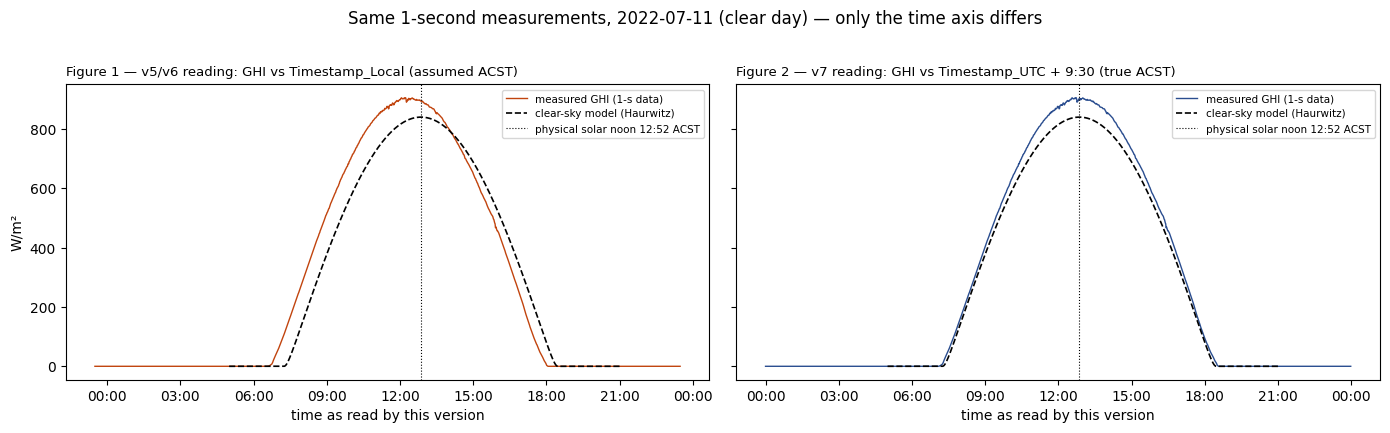

In [ ]:
dsel = pd.Timestamp(CLEAR_DAYS[len(CLEAR_DAYS)//2])
sel = (timestamp_v7.dt.normalize() == dsel).to_numpy()
t5, t7, gv = timestamp_v5[sel], timestamp_v7[sel], df_raw.ghi_wm2[sel]
grid = pd.date_range(dsel + pd.Timedelta(hours=5), dsel + pd.Timedelta(hours=21), freq="1min")
cs_grid = clearsky_haurwitz(solar_geometry(grid, LAT, LON, ACST_OFFSET_H))
noon = physical_solar_noon_acst_hours([dsel])[0]
noon_ts = dsel + pd.Timedelta(hours=noon)
step = max(1, int(round(60 / validation_parsed.median_step_s.iloc[0])))        # plot at ~1-min density

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, tt, title, col in ((ax[0], t5, "Figure 1 — v5/v6 reading: GHI vs Timestamp_Local (assumed ACST)", "#c1440e"),
                          (ax[1], t7, "Figure 2 — v7 reading: GHI vs Timestamp_UTC + 9:30 (true ACST)", "#2a4d8f")):
    a.plot(tt.iloc[::step], gv.iloc[::step], color=col, lw=1, label="measured GHI (1-s data)")
    a.plot(grid, cs_grid, "k--", lw=1.2, label="clear-sky model (Haurwitz)")
    a.axvline(noon_ts, color="k", lw=0.8, ls=":", label=f"physical solar noon {fmt(noon)} ACST")
    a.set_title(title, fontsize=9.5, loc="left"); a.set_xlabel("time as read by this version")
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M")); a.legend(fontsize=7.5)
ax[0].set_ylabel("W/m²")
fig.suptitle(f"Same 1-second measurements, {dsel.date()} (clear day) — only the time axis differs", y=1.02)
plt.tight_layout(); plt.show()

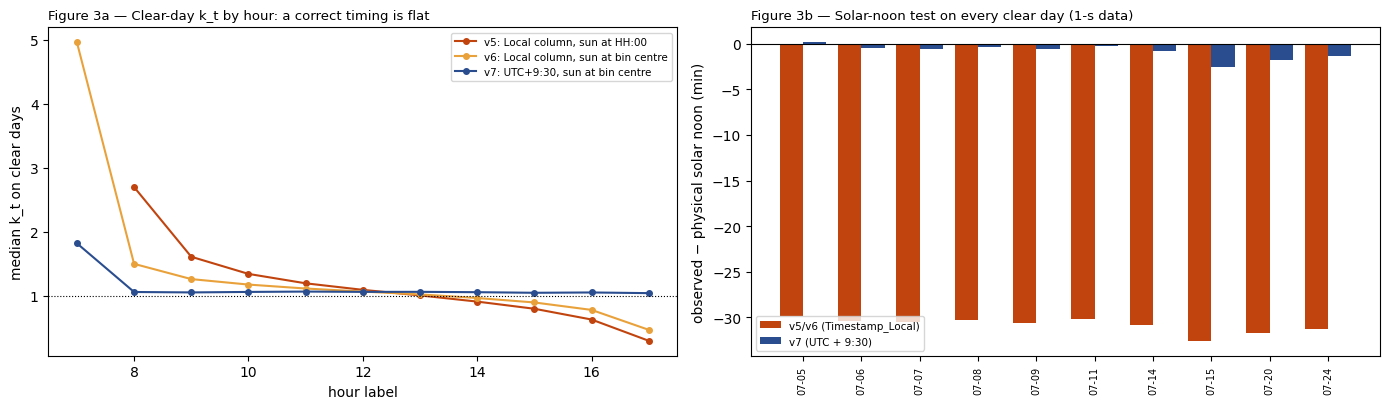

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for c, lab, col in (("kt_v5", "v5: Local column, sun at HH:00", "#c1440e"),
                    ("kt_v6", "v6: Local column, sun at bin centre", "#e9a23b"),
                    ("kt_v7", "v7: UTC+9:30, sun at bin centre", "#2a4d8f")):
    ax[0].plot(prof.index, prof[c], "-o", ms=4, color=col, label=lab)
ax[0].axhline(1.0, color="k", lw=0.8, ls=":")
ax[0].set_xlabel("hour label"); ax[0].set_ylabel("median k_t on clear days")
ax[0].set_title("Figure 3a — Clear-day k_t by hour: a correct timing is flat", fontsize=9.5, loc="left")
ax[0].legend(fontsize=7.5)

x = np.arange(len(noon_check))
ax[1].bar(x - 0.2, noon_check["v5/v6 centroid − noon (min)"], 0.4, color="#c1440e", label="v5/v6 (Timestamp_Local)")
ax[1].bar(x + 0.2, noon_check["v7 centroid − noon (min)"], 0.4, color="#2a4d8f", label="v7 (UTC + 9:30)")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(x); ax[1].set_xticklabels([str(d)[5:] for d in noon_check.day], rotation=90, fontsize=7)
ax[1].set_ylabel("observed − physical solar noon (min)")
ax[1].set_title("Figure 3b — Solar-noon test on every clear day (1-s data)", fontsize=9.5, loc="left")
ax[1].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

## 14. Demonstration of potential misinterpretation

Each consequence is classified as **Demonstrated by the data** (in this notebook) or **Potential, requiring further validation**.

In [ ]:
# lightweight quantitative checks on the window
hourly_by_v = {"v5": hourly_v5, "v6": hourly_v6, "v7": hourly_v7}
rows = []
for v, h in hourly_by_v.items():
    k = h["kt"]
    geomt = {"v5": geom_v5, "v6": geom_v6, "v7": geom_v7}[v]
    elev = 90 - np.degrees(np.arccos(solar_geometry(geomt, LAT, LON, ACST_OFFSET_H)))
    dk = k.diff().abs()
    rows.append({"version": v,
                 "daylight hours": int(k.notna().sum()),
                 f"hours k_t > {KT_MAX} (QC ceiling)": int((k > KT_MAX).sum()),
                 f"ramp hours |Δk_t|>{RAMP_KT}, elev>15°": int(((dk > RAMP_KT) & (elev > 15)).sum()),
                 "clear-day morning−afternoon k_t": float(asym.loc[f"kt_{v}", "morning − afternoon"])})
consequence_metrics = pd.DataFrame(rows)
display(consequence_metrics.round(3))

,version,daylight hours,hours k_t > 1.3 (QC ceiling),"ramp hours |Δk_t|>0.35, elev>15°",clear-day morning−afternoon k_t
0,v5,341,79,31,0.622
1,v6,341,62,33,0.330
2,v7,342,28,30,0.006


| Possible consequence | Status | Evidence |
|---|---|---|
| Solar peak / solar noon appears at the wrong clock time (≈30 min early in v5/v6) | **Demonstrated** | §8 table, Figure 1 vs 2, Figure 3b |
| Irradiance rises earlier (and falls earlier) than it actually did | **Demonstrated** | Figure 1: the measured curve leads the clear-sky model in both morning and evening |
| Hourly GHI values themselves differ (each hour averages a different half-hour of physical time) | **Demonstrated** | §12.1 |
| Forecast target k_t tilted: morning too high, afternoon too low (v5 strongly, v6 half as much) | **Demonstrated** | §12.2, Figure 3a |
| More hours hitting the k_t quality-control ceiling, and different ramp flags | **Demonstrated for this window** | §14 table; magnitude varies by month |
| Persistence baseline and model skill change | **Recorded in the executed pipelines, not recomputed here** | §14.1; also confounded with other v7 changes |
| Irradiance mis-paired with Alice Springs measured PV (the 241 export carries correct local time) | **Potential, supported by pipeline logs** | v7 alignment log: Alice 241 export lag −1.6 min (correct), while the DKASC Local column is UTC+9 (tz_check); not recomputed here |
| Features and target misaligned with each other *within* the Darwin series | **Not supported** | All Darwin columns shift together, so lags and target stay consistent with each other. The misalignment is with the sun (clear-sky geometry), and with any source on a different clock |
| Train/validation/test boundaries moved | **Not materially** | Splits are by sample order; a 30-min relabel moves no sample across a boundary by more than one hour |
| Wrong day assigned to observations | **Not supported** | The error is 30 min and midnight is always dark, so no daylight observation changes date |

### 14.1 Recorded evidence from the executed pipelines (for reference, not recomputed)

These numbers are **copied from the outputs of the executed notebooks** and labelled with their source. They are included so the timing error can be connected to modelling outcomes. They are not reproduced here, because doing so would require retraining.

**Caution.** v6 → v7 also changed the evaluation protocol and extended the Darwin record, so the v6 → v7 differences **cannot be attributed to timing alone**. The v5 → v6 difference used an identical Darwin record, and is attributable to the geometry-instant change (problem B).

| Quantity | v5 | v6 | v7 / v7.1 | Source |
|---|---|---|---|---|
| Darwin diurnal lag, all days (min) | −61.4 (v5 convention on v6 data) | −31.0 | −3.2 | v6 Part 3A table; v7 registry `timing.primary_all_day_lag_min` |
| Darwin diurnal lag, clear days (min) | — | — | −1.3 | v7 registry `timing.primary_clear_day_lag_min` |
| DKASC `Timestamp_Local` − `Timestamp_UTC` (h) | 9.0 (not checked) | 9.0 (not checked) | 9.0 on all 11 files, flagged | v7 `tz_check` |
| Persistence RMSE, Darwin test (W/m²) | 146.8 | 129.3 | 99.2 (different test period and protocol) | v5/v6 Part 9 main table; v7 R2 leaderboard |
| QR-GRU skill vs persistence | +21.8% (seed 42) | +7.0% (seed 42) | +12.1% [10.6, 13.6] (20 runs) | same |

In [ ]:
# optional: if the v7 results registry is on Drive, show the recorded timing values directly from it
reg_path = os.path.join(DATA_ROOT, "_tropicalpv_artifacts", "results_registry.json")
if os.path.exists(reg_path):
    import json
    reg = json.load(open(reg_path))
    keys = [k for k in reg if k.startswith("timing.")]
    display(pd.DataFrame({"registry key": keys, "value": [reg[k]["value"] for k in keys],
                          "note": [reg[k].get("note", "") for k in keys]}))
else:
    print("results_registry.json not found — the recorded values above are quoted from the executed notebooks.")

,registry key,value,note
0,timing.primary_clear_day_lag_min,-1.29,"DARWIN, 771 clear days (daily k >= 0.75)"
1,timing.primary_all_day_lag_min,-3.16,
2,timing.primary_lag_v5_convention_min,-32.11,
3,timing.gate_passed,True,


### 14.2 Optional: does the timing error change the seasonal ramp pattern? (full-year check)

The final report states that a dry-season ramp excess at Darwin in v6 disappeared in v7. v7 also changed the record length, so that statement is **confounded**. This optional check isolates timing: one year, same data, v5/v6 bins versus v7 bins, and nothing else changed.

Set `RUN_FULL_YEAR_RAMP_CHECK = True` in §2 to run it. It reads the whole annual file, which takes about 3–5 minutes.

In [ ]:
if RUN_FULL_YEAR_RAMP_CHECK:
    acc = {}
    t0 = time.time()
    for chunk in pd.read_csv(DARWIN_FILE, skiprows=header_idx, usecols=[COL_UTC, COL_LOCAL] + COLS_IRR,
                             dtype={COL_UTC: str, COL_LOCAL: str}, chunksize=CHUNK_ROWS):
        gch = chunk[COLS_IRR].apply(pd.to_numeric, errors="coerce").mean(axis=1)
        gch = gch.where((gch < 9000) & (gch > -999))
        tu = pd.to_datetime(chunk[COL_UTC], dayfirst=True, errors="coerce")
        tl = pd.to_datetime(chunk[COL_LOCAL], dayfirst=True, errors="coerce")
        for name, tt in (("v5v6", tl), ("v7", tu + pd.Timedelta(hours=ACST_OFFSET_H))):
            hb = tt.dt.floor("h")
            off_s = (tt - hb).dt.total_seconds()                  # seconds within the hour (no int64 overflow)
            s = pd.DataFrame({"h": hb, "g": gch, "o": off_s}).groupby("h").agg(
                g=("g", "sum"), n=("g", "count"), o=("o", "sum"), c=("o", "count"))
            acc[name] = s if name not in acc else acc[name].add(s, fill_value=0)
    print(f"full-year read: {time.time()-t0:.0f}s")
    out = []
    for name, s in acc.items():
        s = s[s.n > 0]
        h = pd.DataFrame({"ts": s.index, "ghi": s.g / s.n})
        geom = pd.DatetimeIndex(s.index) + pd.to_timedelta((s.o / s.c).values, unit="s")   # bin centre
        cosz = solar_geometry(geom, LAT, LON, ACST_OFFSET_H)
        cs = clearsky_haurwitz(cosz)
        with np.errstate(all="ignore"):
            kt = np.where(cs > DAYLIGHT_CS_MIN, h.ghi.values / cs, np.nan)
        elev = 90 - np.degrees(np.arccos(cosz))
        dk = np.abs(np.diff(kt, prepend=np.nan))
        wet = pd.DatetimeIndex(h.ts).month.isin([11, 12, 1, 2, 3, 4])
        valid = (elev > 15) & np.isfinite(dk)
        for season, msk in (("wet", wet), ("dry", ~wet)):
            v = valid & msk
            out.append({"reading": name, "season": season, "hours": int(v.sum()),
                        "ramp_%": 100 * float((dk[v] > RAMP_KT).mean())})
    display(pd.DataFrame(out).pivot(index="reading", columns="season", values="ramp_%").round(2))
    print("If the dry-vs-wet ordering differs between readings, the report's statement is supported by timing alone.")
else:
    print("Skipped (RUN_FULL_YEAR_RAMP_CHECK = False).")

Skipped (RUN_FULL_YEAR_RAMP_CHECK = False).


## 15. How should the data be read?

**One row of a DKASC Darwin 1-second file is one measurement of global horizontal irradiance, taken at the instant given by `Timestamp_UTC`.**

To express that instant in Darwin local time, add **9 hours 30 minutes** (ACST). Do not use `Timestamp_Local`: it is UTC+9:00, and it places every measurement 30 minutes too early.

**An hourly mean** labelled HH:00 (ACST) is the average of the samples from HH:00 to HH:59:59, and describes the instant **~HH:30**. Solar geometry for that hour must be computed at the bin's mean sample time, not at HH:00.

In [ ]:
ex = df_raw.loc[(timestamp_v7.dt.normalize() == dsel).to_numpy() & (timestamp_v7.dt.hour == 12).to_numpy()
                & (timestamp_v7.dt.minute == 0).to_numpy() & (timestamp_v7.dt.second == 0).to_numpy()].head(1)
i = ex.index[0]
hr = hourly_v7[hourly_v7.ts == dsel + pd.Timedelta(hours=12)].iloc[0]
print("Worked example from the data")
print(f"  raw Timestamp_UTC   : {df_raw.at[i, COL_UTC]}")
print(f"  raw Timestamp_Local : {df_raw.at[i, COL_LOCAL]}   <- UTC+9:00, NOT Darwin time")
print(f"  correct Darwin time : {timestamp_v7[i]:%d/%m/%Y %H:%M:%S} ACST (UTC + 9:30)")
print(f"  measured GHI        : {df_raw.at[i, 'ghi_wm2']:.1f} W/m² at that instant")
print(f"  hourly row (v7)     : label {hr.ts:%H:%M} ACST, mean of {int(hr.n_obs):,} samples, "
      f"represents ~{hr.ts + pd.Timedelta(minutes=hr.ts_off_min):%H:%M}, GHI {hr.ghi_wm2:.1f} W/m², k_t {hr.kt:.3f}")

Worked example from the data
  raw Timestamp_UTC   : 11/07/2022 02:30:00
  raw Timestamp_Local : 11/07/2022 11:30:00   <- UTC+9:00, NOT Darwin time
  correct Darwin time : 11/07/2022 12:00:00 ACST (UTC + 9:30)
  measured GHI        : 876.0 W/m² at that instant
  hourly row (v7)     : label 12:00 ACST, mean of 3,600 samples, represents ~12:29, GHI 893.9 W/m², k_t 1.069


## 16. Why this matters to the research

* **Time-series integrity and temporal consistency.** Within the Darwin series the error is a constant shift, so the order and spacing of observations are intact. What breaks is the series' relationship to **the sun** and to **any other source** that uses a correct clock.
* **Feature–target alignment.** k_t lags and the k_t target shift together, so they stay aligned with each other. But **every** k_t value is computed against a sun that is 30–60 minutes out of place. The target is distorted, not misaligned.
* **Solar and PV patterns.** Clear days appear to have morning cloud enhancement and afternoon thinning that do not exist (§12.2). Peak timing appears 30 minutes early (§8).
* **Forecasting horizon, training, validation and testing.** The 1-hour-ahead structure is intact. The learned relationship, and the persistence baseline it is scored against, are computed from a biased target. The v5 → v6 change in skill on an identical record shows that this bias moves the results.
* **Reproducibility and validity.** Nothing in the files warns that the `Local` column is not ACST. Only a physical timing check exposes it, so a timing check belongs in any pipeline that uses these exports.

**Does the issue affect interpretation, the modelling data, or both?**

**Both.**

* The **raw one-second measurements are unaffected**. They are the same numbers under every reading.
* **Problem A** changes which samples form each hour, so it changes the **hourly modelling data** (GHI means, labels and k_t).
* **Problem B** changes **k_t** only.
* Their **interpretation** (timing of peaks, sunrise and sunset) is affected by A.

## 17. Before vs after summary

| Aspect | v5 | v6 | v7 (actual correction) | Research implication |
|---|---|---|---|---|
| Timestamp column used | `Timestamp_Local` (UTC+9:00) | `Timestamp_Local` (unchanged) | `Timestamp_UTC` + 9:30 | Only v7 places data on Darwin's clock |
| Timezone handling | Implicit; label assumed ACST | Implicit; unchanged | Explicit conversion from UTC; offset measured and checked | Assumption becomes evidence |
| Within-hour instant for solar geometry | HH:00 (bin start) | Mean sample time (~HH:30) | Mean sample time | Correct representative instant from v6 on |
| Net timing error vs the sun (Darwin) | ≈ −60 min | ≈ −30 min | ≈ 0 (−1.3 min on clear days) | k_t unbiased only in v7 |
| Hourly GHI values | Bins = ACST HH:30–HH+1:30 | Identical to v5 | Bins = ACST HH:00–HH+1:00 | A changes the modelling data |
| Clear-sky index k_t | Strong morning-high / afternoon-low tilt | Tilt halved | Flat on clear days | Target and persistence baseline differ by version |
| Raw 1-s measurements | Unchanged | Unchanged | Unchanged | No measurement was corrupted |
| Timing validation | None | Lag check, threshold ±45 min (−31 passed) | Clear-day lag gate ±10 min; run stops on failure | Error cannot pass silently |

## 18. Final technical conclusion

1. **What was wrong in v5?** Two stacked timing errors:
   * (A) it used `Timestamp_Local`, which the data show is **UTC+9:00, 30 min behind ACST**;
   * (B) it evaluated the sun at the start of each hourly bin rather than at its centre.

   Together these placed the clear-sky model about **60 min out of step** with the measurements.
2. **What did v6 change?** It corrected **B only**, computing the sun at each bin's mean sample time. It kept `Timestamp_Local`, so its hourly values are identical to v5's, and a **~30 min error remained**. v6's own diurnal-lag check measured it (−31 min) but let it pass, because the threshold was ±45 min.
3. **Why is the corrected interpretation more appropriate?** The physical solar-noon test on the raw one-second data puts observed and astronomical noon together **only** under the UTC + 9:30 reading. That reading also matches the legal time zone of the Northern Territory, which has no DST. This correction was made in **v7**, not v6.
4. **What could be misunderstood if v5 (or v6) were used without clarification?**
   * Solar peaks appearing 30 min early.
   * Clear days that look partly cloudy in k_t.
   * A distorted forecasting target and persistence baseline.
   * Irradiance mis-paired with correctly timed sources such as the Alice Springs PV export.
5. **Methodology or only interpretation?** **Both.** The hourly modelling data (values, labels and k_t) change. The raw measurements do not.
6. **What should the final research use?** The **v7/v7.1 pipeline**: UTC column → ACST, geometry at the sample centre, and a clear-day timing gate. The written report should describe v6's change as a *partial* correction.

## 19. Reproducibility / environment information

In [ ]:
import matplotlib
print(f"Python     : {sys.version.split()[0]}  ({platform.platform()})")
print(f"pandas     : {pd.__version__}   numpy: {np.__version__}   matplotlib: {matplotlib.__version__}")
print(f"Data file  : {DARWIN_FILE}")
print(f"Window     : {WINDOW_UTC} UTC   rows: {N_RAW:,}   clear days used: {len(CLEAR_DAYS)}")
print(f"Site       : lat {LAT}, lon {LON}, ACST = UTC+{ACST_OFFSET_H}")
print("No data were written, dropped, interpolated or resampled outside the explicitly shown hourly "
      "aggregations; df_raw is unchanged:", len(df_raw) == N_RAW)

Python     : 3.13.15  (Linux-6.6.122+-x86_64-with-glibc2.39)
pandas     : 2.2.3   numpy: 2.1.3   matplotlib: 3.10.0
Data file  : /content/drive/MyDrive/Data-DKASC Darwin/fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv
Window     : ('2022-07-01', '2022-08-01') UTC   rows: 2,678,400   clear days used: 10
Site       : lat -12.4256, lon 130.8916, ACST = UTC+9.5
No data were written, dropped, interpolated or resampled outside the explicitly shown hourly aggregations; df_raw is unchanged: True
